In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [22]:
df = pd.read_csv('data/penguins.csv',sep=',')

In [23]:
df.isna().sum()

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

In [24]:
datas = df.dropna()
datas.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [25]:
datas.isna().sum()

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [26]:
datas_num = datas.select_dtypes(include='number')
datas_num = (datas_num-datas_num.min())/(datas_num.max()-datas_num.min())
datas_num.min(),datas_num.max()

(culmen_length_mm     0.0
 culmen_depth_mm      0.0
 flipper_length_mm    0.0
 body_mass_g          0.0
 dtype: float64,
 culmen_length_mm     1.0
 culmen_depth_mm      1.0
 flipper_length_mm    1.0
 body_mass_g          1.0
 dtype: float64)

In [27]:
rc = {'font.family':'SimHei','axes.unicode_minus':False}
sns.set(font_scale=0.9,rc=rc)

In [28]:
corr_matrix = datas_num.corr()
corr_matrix

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,1.000000,-0.229465,0.021238,0.588891
culmen_depth_mm,-0.229465,1.000000,0.045725,-0.471071
flipper_length_mm,0.021238,0.045725,1.000000,0.048323
body_mass_g,0.588891,-0.471071,0.048323,1.000000


d:\Anaconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 45 (-) missing from font(s) SimHei.
  fig.canvas.draw()
d:\Anaconda3\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 46 (.) missing from font(s) SimHei.
  fig.canvas.draw()
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 46 (.) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 45 (-) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


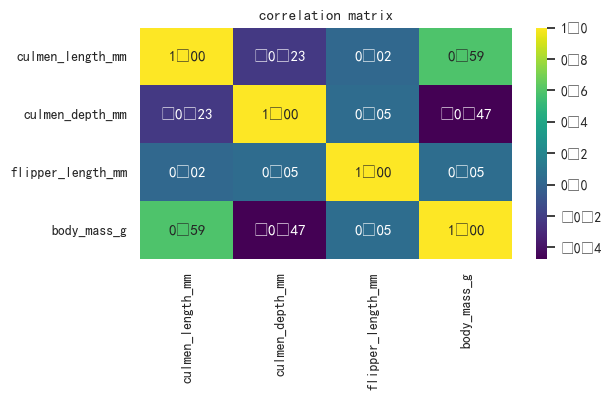

In [29]:
plt.figure(figsize=(6,3))
sns.heatmap(corr_matrix,annot=True,cmap='viridis',fmt='.2f')
plt.title('correlation matrix')
plt.show()

In [30]:
from sklearn.decomposition import PCA

In [37]:
df.loc[df['sex'] == 'MALE','sex'] = 0
df.loc[df['sex'] == '.','sex'] = 0
df.loc[df['sex'] == 'FEMALE','sex'] = 1
df = df.dropna()
df.sex

0      0
1      1
2      1
4      1
5      0
      ..
338    1
340    1
341    0
342    1
343    0
Name: sex, Length: 335, dtype: object

In [38]:
pca_data = df.dropna()

In [40]:
pca_data = (pca_data - pca_data.min())/(pca_data.max()-pca_data.min())

In [41]:
pca = PCA(n_components=3,random_state=57)
X_3d = pca.fit_transform(pca_data)
X_3d.shape

(335, 3)

<function matplotlib.pyplot.show(close=None, block=None)>

d:\Anaconda3\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 45 (-) missing from font(s) SimHei.
  func(*args, **kwargs)
d:\Anaconda3\Lib\site-packages\IPython\core\events.py:82: UserWarning: Glyph 46 (.) missing from font(s) SimHei.
  func(*args, **kwargs)
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 45 (-) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 46 (.) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


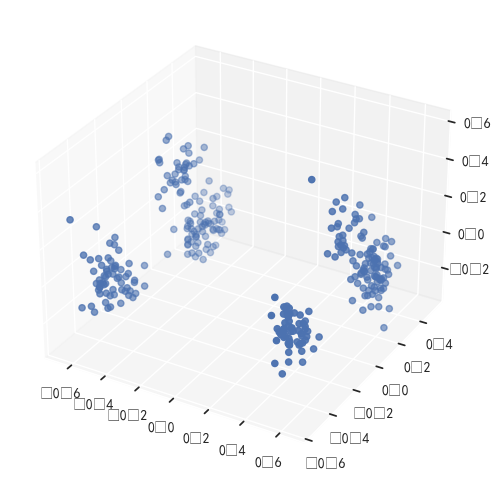

In [42]:
fig = plt.figure(figsize=(12,6))
ax = fig.add_subplot(111,projection='3d')
ax.set_facecolor('white')
ax.scatter(X_3d[:,0],X_3d[:,1],X_3d[:,2])
plt.show